# Risk-limit briefing

Santiago Diaz Ricagno, Lead Data Scientist.

This notebook reads the tables and charts written by `python run_backtest.py`. It does not refit the models. The out-of-sample window is 18 April 2007 to 17 November 2025, 4,678 sessions on each book.

In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path('..').resolve() if Path('../results').exists() else Path('.').resolve()
results = ROOT / 'results'
ranking = pd.read_csv(results / 'limit_ranking.csv')
scores = pd.read_csv(results / 'vol_scores.csv')
tests = pd.read_csv(results / 'var_tests.csv')
tails = pd.read_csv(results / 'tail_gaps.csv')
qlike = scores.groupby('model')['qlike'].mean().sort_values()
print('Equal-weight QLIKE')
print(qlike.round(4).to_string())
print()
print(ranking.round(4).to_string(index=False))


Equal-weight QLIKE
model
gjr_t       1.3476
gjr_n       1.3498
egarch_t    1.3534
egarch_n    1.3586
garch_t     1.3746
garch_n     1.3776
ewma        1.4035
gb_rv       1.5342

 rank    model  zone_penalty  kupiec_failures  hit_mad  qlike
    1    gjr_t             5                3   0.0045 1.3476
    2  garch_t             5                3   0.0050 1.3746
    3 egarch_t             6                3   0.0057 1.3534
    4    gjr_n             6                3   0.0118 1.3498
    5  garch_n             7                3   0.0110 1.3776
    6     ewma             7                3   0.0133 1.4035
    7 egarch_n             8                3   0.0122 1.3586
    8    gb_rv            12                3   0.0107 1.5342


GJR-t is first on QLIKE and first on the 99% limit rule (crisis-review zone penalty, then distance of the hit rate from 1%, then QLIKE). The boosting baseline is last on both.

In [2]:
var99 = tests.loc[tests['level'].round(3).eq(0.99), [
    'ticker', 'model', 'n_exceptions', 'hit_rate', 'kupiec_pvalue', 'ind_pvalue',
    'basel_zone', 'basel_gfc', 'exceptions_gfc', 'basel_covid', 'exceptions_covid', 'shortfall_ratio'
]].copy()
keep = var99['model'].isin(['gjr_t', 'gjr_n', 'garch_t', 'garch_n', 'ewma'])
view = var99.loc[keep].sort_values(['ticker', 'hit_rate'])
print(view.round(4).to_string(index=False))


ticker   model  n_exceptions  hit_rate  kupiec_pvalue  ind_pvalue basel_zone basel_gfc  exceptions_gfc basel_covid  exceptions_covid  shortfall_ratio
   EEM   gjr_t            72    0.0154         0.0006      0.9153     yellow    yellow               5      yellow                 8           0.9804
   EEM garch_t            74    0.0158         0.0002      0.8694        red    yellow               5      yellow                 8           0.9849
   EEM garch_n            86    0.0184         0.0000      0.3048        red    yellow               5      yellow                 8           1.0701
   EEM   gjr_n            96    0.0205         0.0000      0.4368        red    yellow               9      yellow                 9           1.0396
   EEM    ewma           100    0.0214         0.0000      0.5694        red    yellow               6      yellow                 8           1.0994
   FEZ garch_t            62    0.0133         0.0331      0.8472     yellow    yellow              

Gaussian 99% limits run near 2.1–2.5% exceptions. GJR-t runs at 1.35–1.54%. Independence is not rejected for GJR-t. The S&P 250-session review from 1 September 2008 is green (4 exceptions) for GJR-t and yellow (9) for GJR-normal. The review from 15 February 2020 is yellow for GJR-t and red for S&P EWMA.

In [3]:
gjr = tails.loc[tails['student'].eq('gjr_t'), [
    'ticker', 'window', 'var_ratio_99', 'es_ratio_99', 'hit_rate_student', 'hit_rate_normal', 'mean_nu'
]].copy()
print(gjr.round(3).to_string(index=False))


ticker     window  var_ratio_99  es_ratio_99  hit_rate_student  hit_rate_normal  mean_nu
   EEM       full         1.061        1.121             0.015            0.021   12.498
   EEM   gfc_2008         1.099        1.164             0.027            0.048   10.590
   EEM covid_2020         1.073        1.138             0.077            0.077   10.279
   EEM  calm_2017         1.027        1.075             0.004            0.004   12.585
   FEZ       full         1.106        1.227             0.013            0.021    7.154
   FEZ   gfc_2008         1.103        1.198             0.027            0.034    7.850
   FEZ covid_2020         1.251        1.498             0.058            0.058    4.264
   FEZ  calm_2017         1.078        1.232             0.000            0.000    5.317
   SPX       full         1.108        1.221             0.015            0.024    7.486
   SPX   gfc_2008         1.131        1.227             0.021            0.041    7.877
   SPX covid_2020    

In February–April 2020 the GJR degrees of freedom on the S&P and the EURO STOXX 50 book fall to about 4.5. The 99% VaR is then 19–25% above the Gaussian GJR limit, and expected shortfall is 39–50% above it. Full-sample QLIKE barely changes between GJR-t and GJR-normal. The tail shows up in the limit, not in the variance loss.

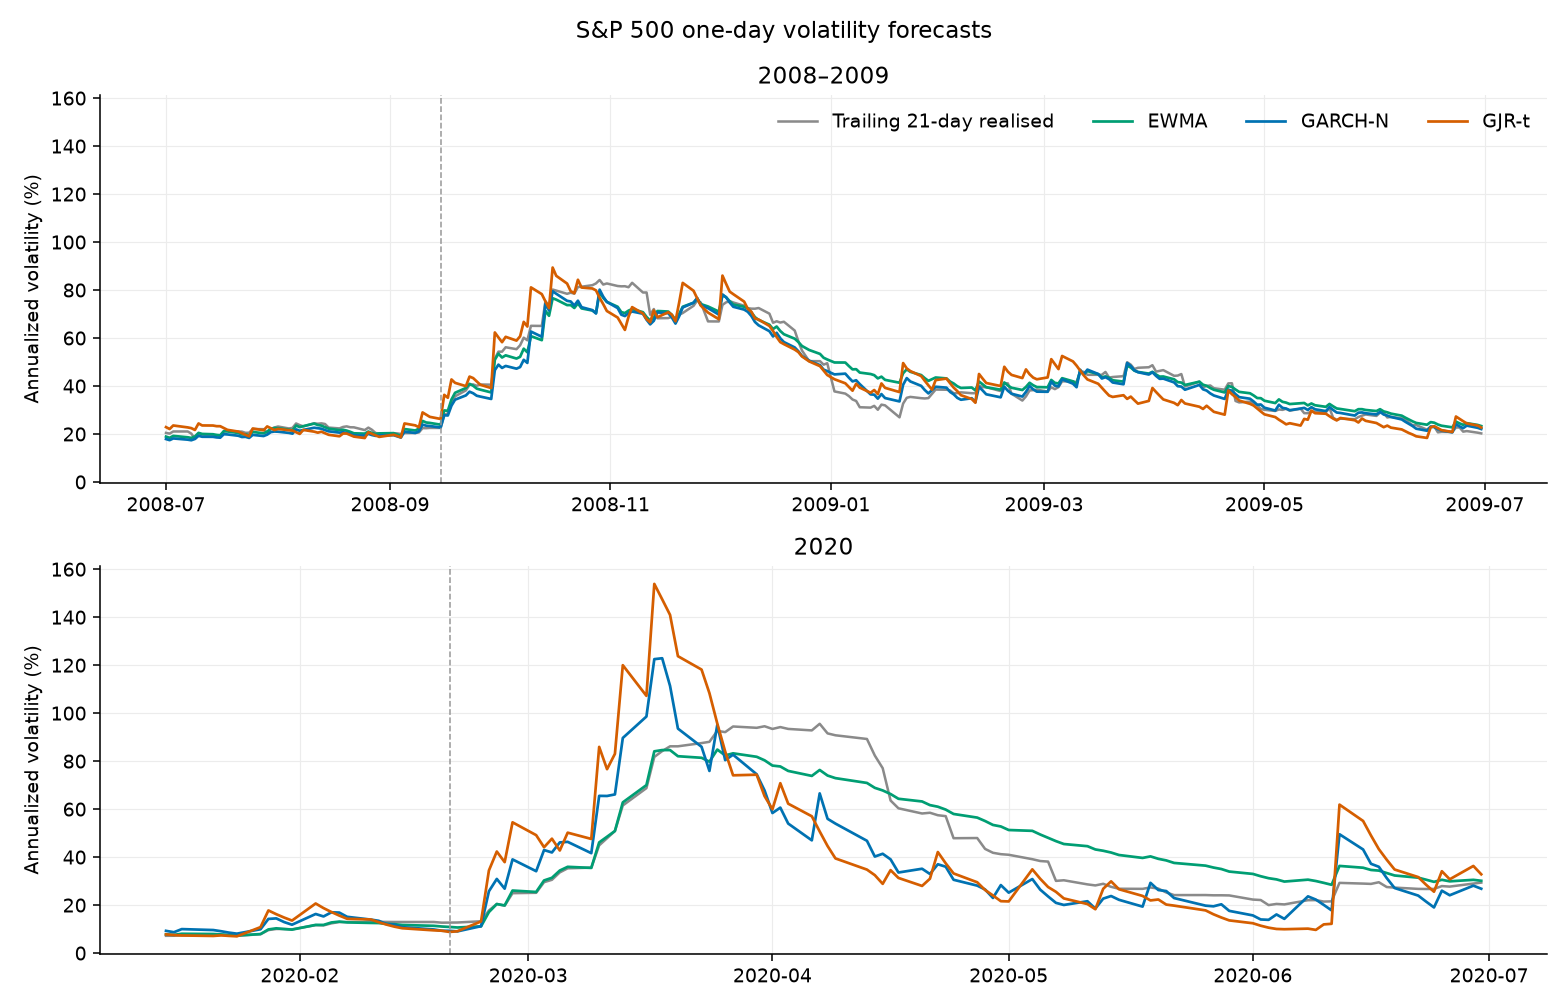

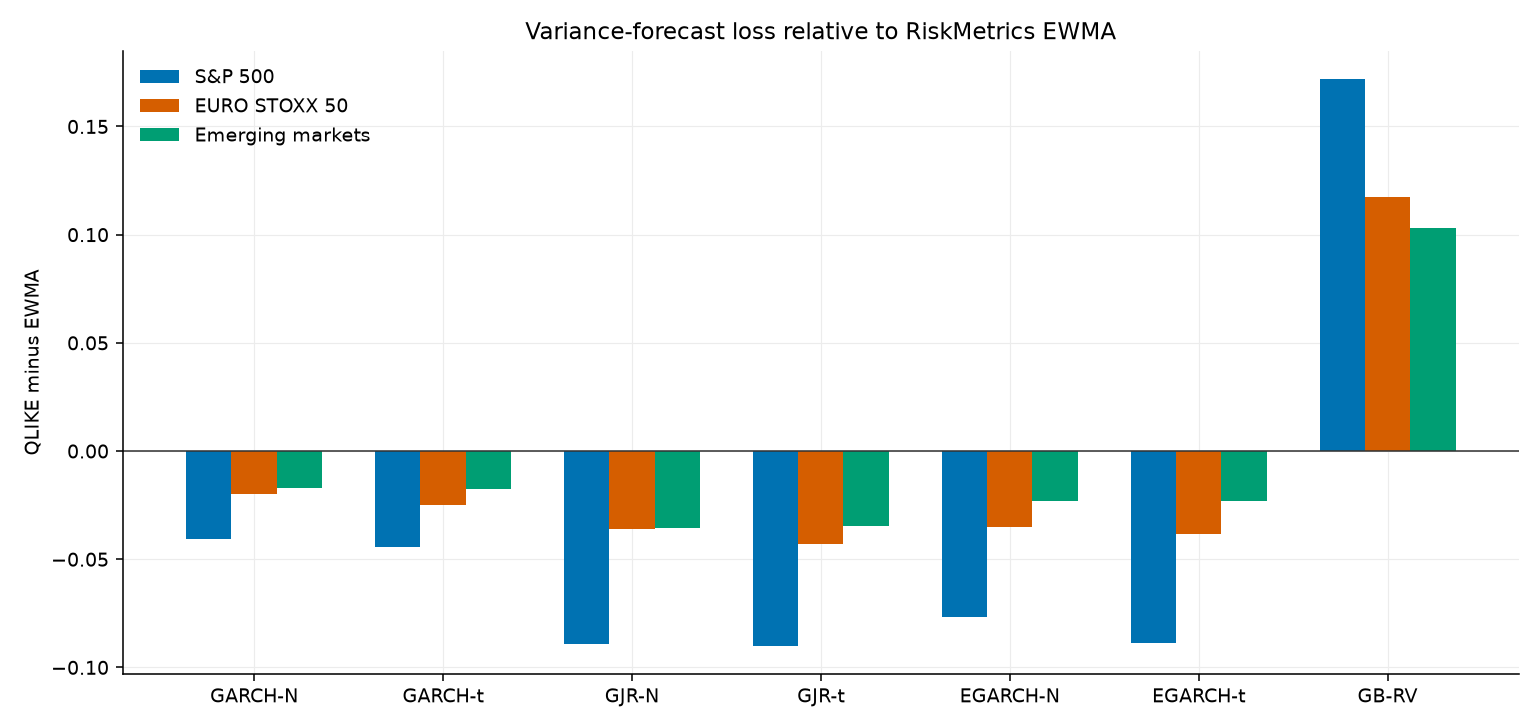

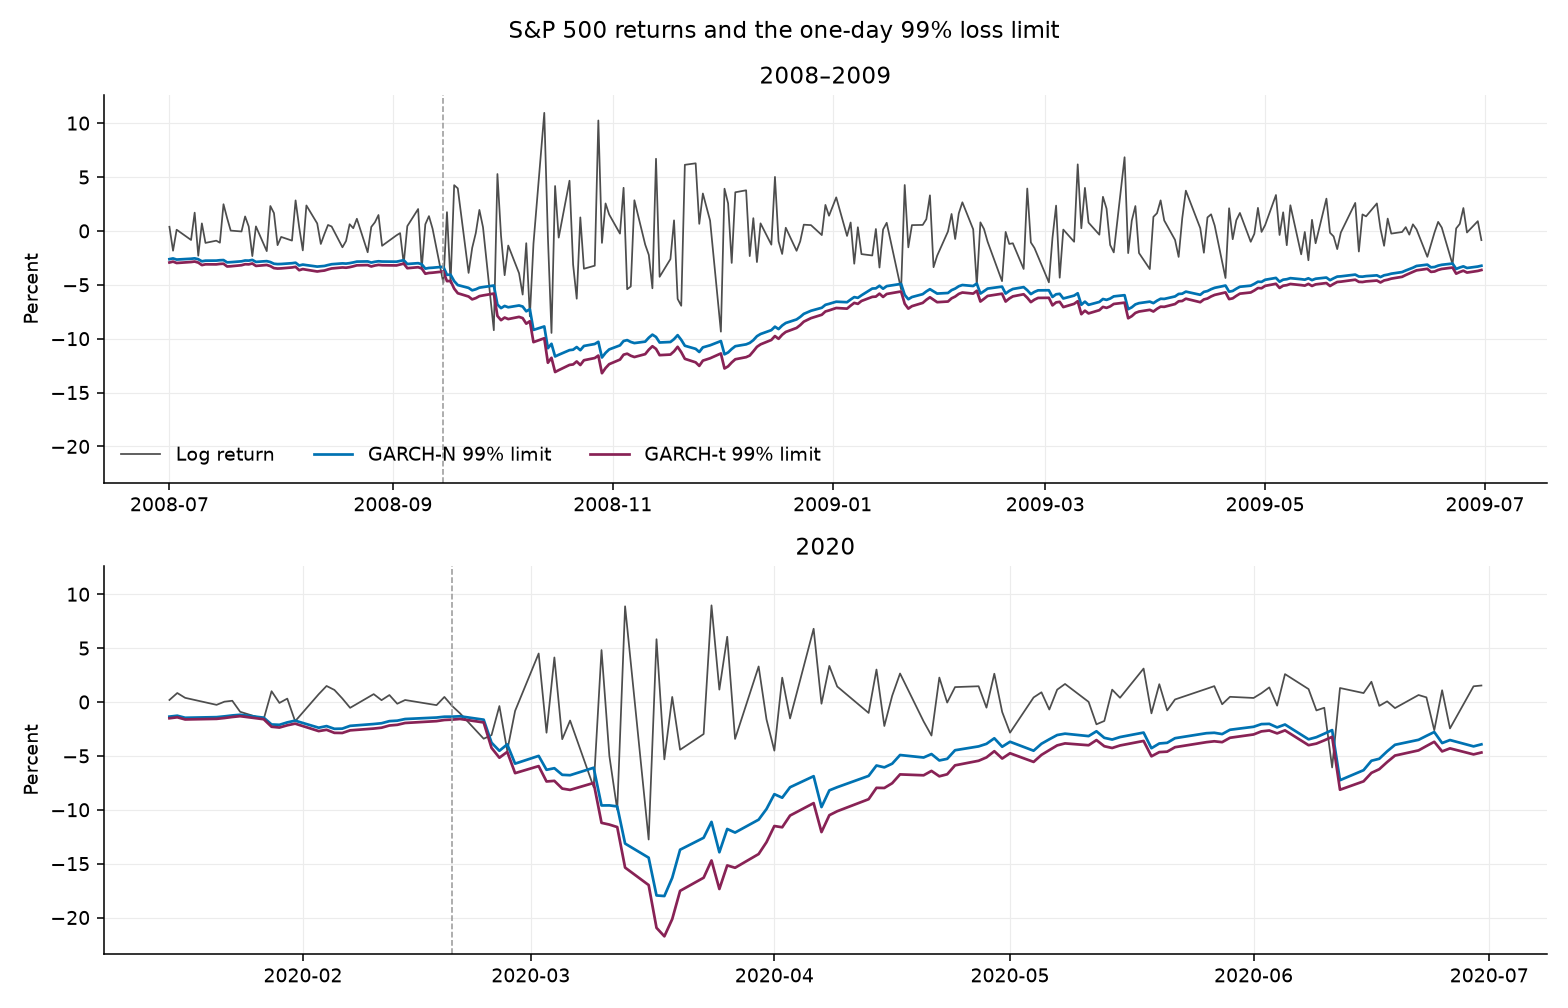

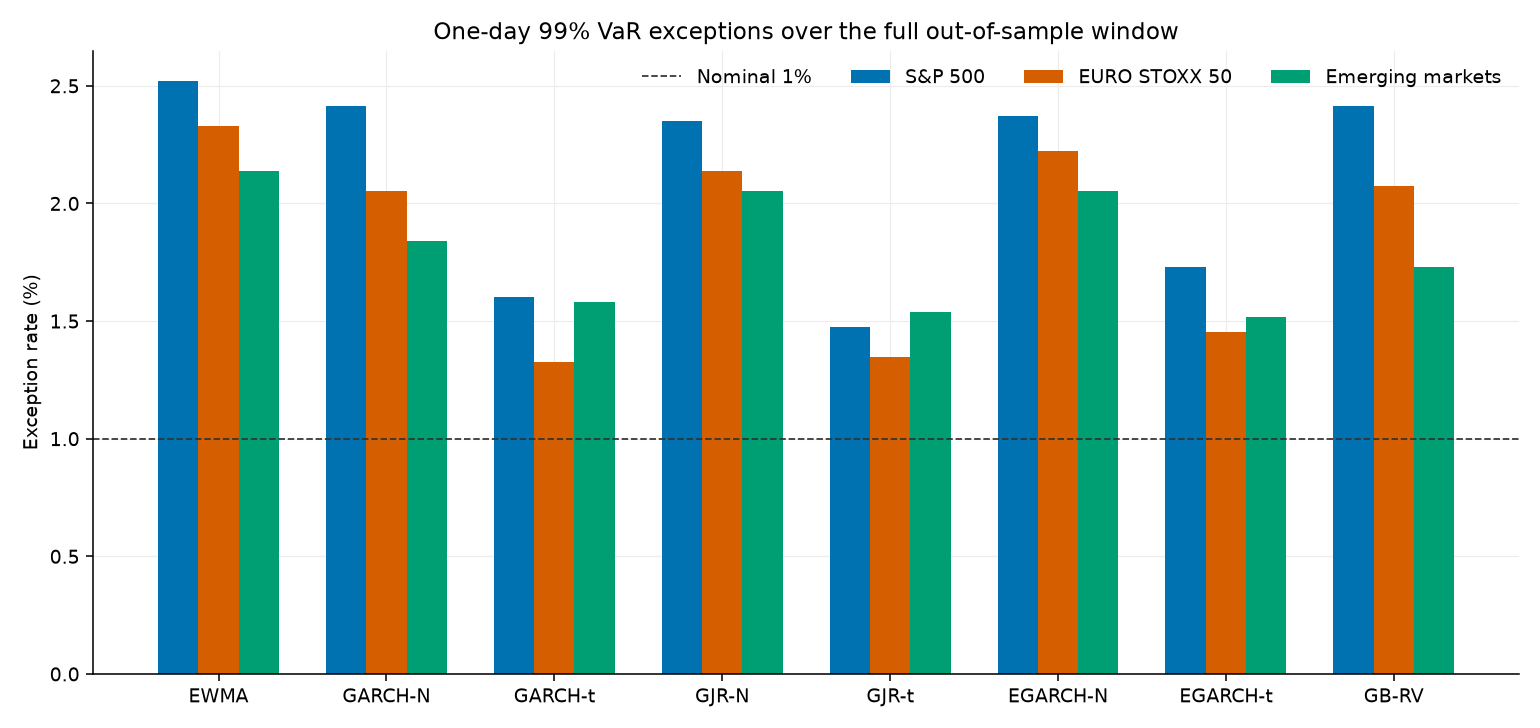

In [4]:
from IPython.display import Image, display
docs = ROOT / 'docs'
for name in [
    'spx_crisis_volatility.png',
    'qlike_versus_ewma.png',
    'spx_var_limits.png',
    'var99_hit_rates.png',
]:
    display(Image(filename=str(docs / name)))
